In [369]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# step1. Load the dataset
## 1. we can collect dataset from any websites, govt org,pvt orgs,ngos,kaggale dataset,data.gov....etc
## 2. using pandas library i had loaded the data and converted into dataframe
## 3. i had verified no of rows and columns present in the dataset
## 4. i had verified information related to all columns like column and its datatype...etc

In [370]:
df = pd.read_excel('pima-data.xlsx')
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,has_diabetes,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True,True
5,5,116,74,0,0,25.6,0.201,30,0,0.0000,False,False
6,3,78,50,32,88,31.0,0.248,26,1,1.2608,True,True
7,10,115,0,0,0,35.3,0.134,29,0,0.0000,False,False
8,2,197,70,45,543,30.5,0.158,53,1,1.7730,True,True
9,8,125,96,0,0,0.0,0.232,54,1,0.0000,True,True


In [371]:
df.shape

(768, 12)

In [372]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_preg       768 non-null    int64  
 1   glucose_conc   768 non-null    int64  
 2   diastolic_bp   768 non-null    int64  
 3   thickness      768 non-null    int64  
 4   insulin        768 non-null    int64  
 5   bmi            768 non-null    float64
 6   diab_pred      768 non-null    float64
 7   age            768 non-null    int64  
 8   diabetes_orig  768 non-null    int64  
 9   skin           768 non-null    float64
 10  has_diabetes   768 non-null    bool   
 11  diabetes       768 non-null    bool   
dtypes: bool(2), float64(3), int64(7)
memory usage: 61.6 KB


In [373]:
pd.set_option('display.max_rows',None)

In [374]:
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,has_diabetes,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True,True
5,5,116,74,0,0,25.6,0.201,30,0,0.0000,False,False
6,3,78,50,32,88,31.0,0.248,26,1,1.2608,True,True
7,10,115,0,0,0,35.3,0.134,29,0,0.0000,False,False
8,2,197,70,45,543,30.5,0.158,53,1,1.7730,True,True
9,8,125,96,0,0,0.0,0.232,54,1,0.0000,True,True


# step2: cleaning the dataset

## 1. identify the null values present in the dataset

In [375]:
df.isnull().sum()

,0
num_preg,0
glucose_conc,0
diastolic_bp,0
thickness,0
insulin,0
bmi,0
diab_pred,0
age,0
diabetes_orig,0
skin,0


In [376]:
df.isnull().values.any()

np.False_

In [377]:
# pip install seaborn

In [378]:
# import seaborn as sns
# # df = sns.load_dataset("iris")
# # corr = df.select_dtypes(include="number").corr()
# corr = df.corr()
# # Draw the heatmap
# plt.figure(figsize=(8, 6))
# sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
# plt.title("Correlation Heatmap")
# plt.show()

## 2. check the correlation between two columns

In [379]:
def check_corr():
    corr = df.corr()
    fig,ax=plt.subplots(figsize=(12,12))
    cmap='plasma'
    ax.matshow(corr,cmap=cmap)
    plt.xticks(range(len(df.columns)),corr.columns,rotation=45)
    plt.yticks(range(len(df.columns)),corr.columns)
    plt.show()

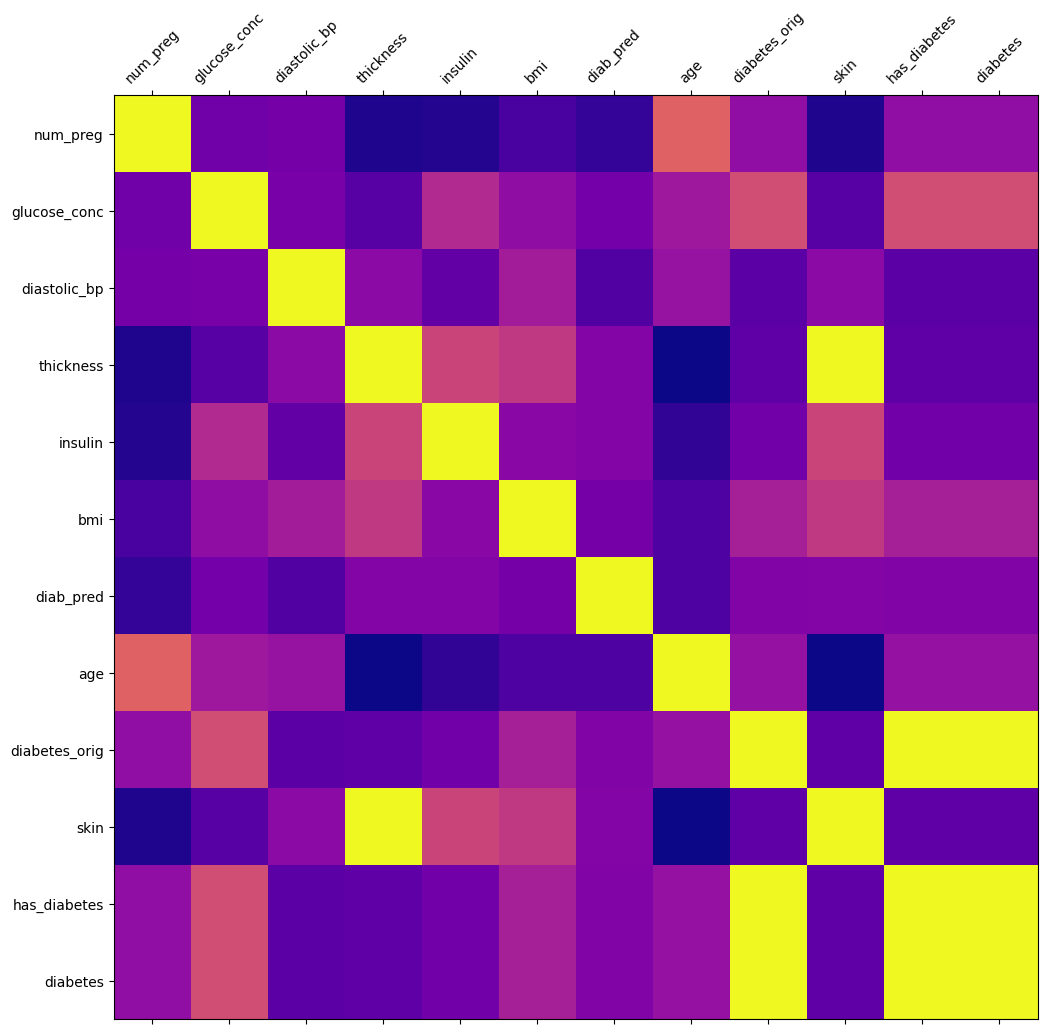

In [380]:
check_corr()

## thickness and skin are correlated to each other
## diabetes_org and diabetes are corerelated to each other


## 3. drop the correlated columns

In [381]:
df.drop('thickness',axis=1,inplace=True)
df.drop('diabetes_orig',axis=1,inplace=True)

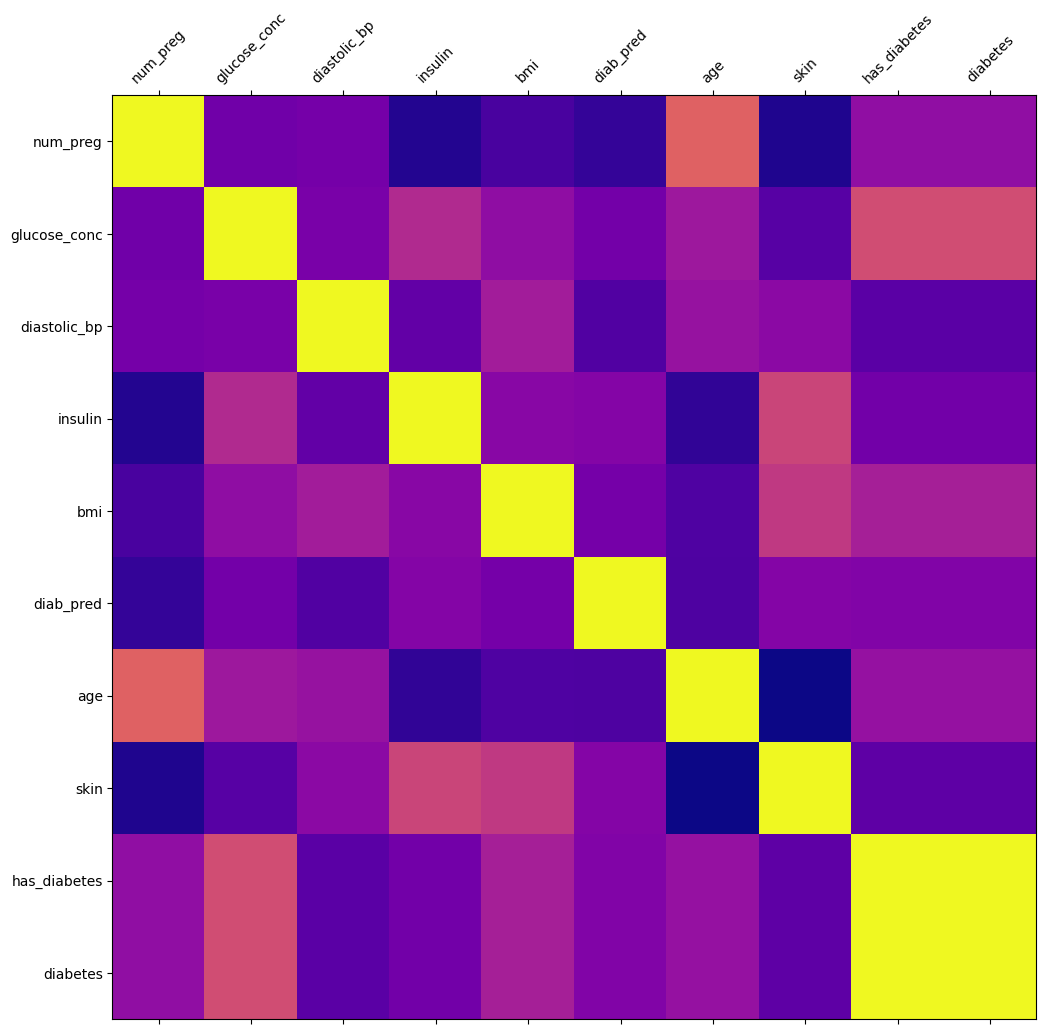

In [382]:
check_corr()

## 4. convert data into integer values

In [383]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,has_diabetes,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True,True
1,1,85,66,0,26.6,0.351,31,1.1426,False,False
2,8,183,64,0,23.3,0.672,32,0.0000,True,True
3,1,89,66,94,28.1,0.167,21,0.9062,False,False
4,0,137,40,168,43.1,2.288,33,1.3790,True,True


In [384]:
dict1 = {"diabetes":[True,False]}
dict2 = {"diabetes":[1,0]}

df.replace(dict1,dict2,inplace=True)

/tmp/ipykernel_1088/1929047261.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace(dict1,dict2,inplace=True)


In [385]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,has_diabetes,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True,1
1,1,85,66,0,26.6,0.351,31,1.1426,False,0
2,8,183,64,0,23.3,0.672,32,0.0000,True,1
3,1,89,66,94,28.1,0.167,21,0.9062,False,0
4,0,137,40,168,43.1,2.288,33,1.3790,True,1


## 5. check the dataset is balanced or not

In [386]:
num_true=len(df[df['diabetes'] == 1])
num_false=len(df[df['diabetes'] == 0])
print(num_true)
print(num_false)
true_percentage=((num_true)/(num_true+num_false))*100
print(true_percentage)
false_percentage=((num_false)/(num_true+num_false))*100
print(false_percentage)

268
500
34.89583333333333
65.10416666666666


# 3. Train Test split

In [387]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi',
       'diab_pred', 'age', 'skin', 'has_diabetes', 'diabetes'],
      dtype='object')

In [388]:
# pip install scikit-learn

In [389]:
from sklearn.model_selection import train_test_split
input_columns =['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi','diab_pred', 'age', 'skin']
output_columns=['diabetes']

x = df[input_columns].values
y = df[output_columns].values
split_test_size = 0.3
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=split_test_size,random_state=42)

In [390]:
# def m1(x,y):
#     s1 = x+y
#     s2 = x-y
#     return s1,s2
# sub1,sum1=m1(10,20)
# print(sum1)
# print(sub1)

In [391]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(537, 8)
(537, 1)
(231, 8)
(231, 1)


In [392]:
print('{0:0.2f} in training set:'.format(len(x_train)/len(df.index)*100))
print('{0:0.2f} in testing set:'.format(len(x_test)/len(df.index)*100))

69.92 in training set:
30.08 in testing set:


In [393]:
print('training_true {0} ({1:0.2f}%) in training set:'.format(len(y_train[y_train[:] == 1]),
                                                              (len(y_train[y_train[:] == 1])/len(y_train)*100)))


print('training_false {0} ({1:0.2f}%) in training set:'.format(len(y_train[y_train[:] == 0]),
                                                               (len(y_train[y_train[:] == 0])/len(y_train)*100)))
print('testing_true {0} ({1:0.2f}%) in testing set:'.format(len(y_test[y_test[:] == 1]),
                                                            (len(y_test[y_test[:] == 1])/len(y_test)*100)))
print('testing_false {0} ({1:0.2f}%) in testing set:'.format(len(y_test[y_test[:] == 0]),
                                                             (len(y_test[y_test[:] == 0])/len(y_test)*100)))


training_true 188 (35.01%) in training set:
training_false 349 (64.99%) in training set:
testing_true 80 (34.63%) in testing set:
testing_false 151 (65.37%) in testing set:


In [394]:
# print('the sum of {0} and {1} is {2}'.format(10,20,10+20))
# print('the sum of {1} and {0} is {2}'.format(10,20,10+20))

# step4 : Post Split data preparation

In [395]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi',
       'diab_pred', 'age', 'skin', 'has_diabetes', 'diabetes'],
      dtype='object')

In [396]:
print(f"no of rows contains  in df: {len(df)}")
print(f"rows contains 0 values in num_preg column {len(df.loc[df['num_preg']==0])}")
print(f"rows contains 0 values in glucose_conc column {len(df.loc[df['glucose_conc']==0])}")
print(f"rows contains 0 values in diastolic_bp column {len(df.loc[df['diastolic_bp']==0])}")
print(f"rows contains 0 values in insulin column {len(df.loc[df['insulin']==0])}")
print(f"rows contains 0 values in bmi column {len(df.loc[df['bmi']==0])}")
print(f"rows contains 0 values in diab_pred column {len(df.loc[df['diab_pred']==0])}")
print(f"rows contains 0 values in age column {len(df.loc[df['age']==0])}")
print(f"rows contains 0 values in skin column {len(df.loc[df['skin']==0])}")


no of rows contains  in df: 768
rows contains 0 values in num_preg column 111
rows contains 0 values in glucose_conc column 5
rows contains 0 values in diastolic_bp column 35
rows contains 0 values in insulin column 374
rows contains 0 values in bmi column 11
rows contains 0 values in diab_pred column 0
rows contains 0 values in age column 0
rows contains 0 values in skin column 227


## SimpleImputer

In [397]:
from sklearn.impute import SimpleImputer
fill_zeros=SimpleImputer(missing_values=0,strategy='mean')
x_train = fill_zeros.fit_transform(x_train)
x_test =fill_zeros.transform(x_test)

In [398]:
x_train[:5]

array([[1.00000000e+00, 9.50000000e+01, 6.00000000e+01, 5.80000000e+01,
        2.39000000e+01, 2.60000000e-01, 2.20000000e+01, 7.09200000e-01],
       [5.00000000e+00, 1.05000000e+02, 7.20000000e+01, 3.25000000e+02,
        3.69000000e+01, 1.59000000e-01, 2.80000000e+01, 1.14260000e+00],
       [4.34056399e+00, 1.35000000e+02, 6.80000000e+01, 2.50000000e+02,
        4.23000000e+01, 3.65000000e-01, 2.40000000e+01, 1.65480000e+00],
       [4.00000000e+00, 1.31000000e+02, 6.80000000e+01, 1.66000000e+02,
        3.31000000e+01, 1.60000000e-01, 2.80000000e+01, 8.27400000e-01],
       [1.00000000e+00, 1.03000000e+02, 3.00000000e+01, 8.30000000e+01,
        4.33000000e+01, 1.83000000e-01, 3.30000000e+01, 1.49720000e+00]])

In [399]:
X_test_original = x_test.copy()

## standardization

In [400]:
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
x_train = scalar.fit_transform(x_train)
x_test = scalar.transform(x_test)

In [401]:
x_train[:5]
# x_test[:5]

array([[-1.15687814e+00, -8.96200501e-01, -1.00392807e+00,
        -1.14563966e+00, -1.20379368e+00, -6.14216360e-01,
        -9.48610283e-01, -1.25782829e+00],
       [ 2.28370750e-01, -5.64089421e-01, -1.97904130e-02,
         1.99702256e+00,  6.64529988e-01, -9.09737865e-01,
        -4.34666726e-01,  4.16397301e-02],
       [ 6.15174086e-16,  4.32243819e-01, -3.47836300e-01,
         1.11425228e+00,  1.44060290e+00, -3.06991033e-01,
        -7.77295764e-01,  1.57737467e+00],
       [-1.17941473e-01,  2.99399387e-01, -3.47836300e-01,
         1.25549552e-01,  1.18404607e-01, -9.06811910e-01,
        -4.34666726e-01, -9.03427923e-01],
       [-1.15687814e+00, -6.30511637e-01, -3.46427222e+00,
        -8.51382901e-01,  1.58432010e+00, -8.39514933e-01,
        -6.38042901e-03,  1.10484084e+00]])

# step5: training the model

In [402]:
# y_train[:5]

In [403]:
y_train=y_train.astype(int).ravel()
y_test=y_test.astype(int).ravel()

In [404]:
# y_train[:5]

## train a model using navie bayees

In [405]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(x_train,y_train)

GaussianNB()

In [406]:
from sklearn import metrics
nb_model_predict = nb_model.predict(x_train)
print(metrics.accuracy_score(y_train,nb_model_predict))

0.7541899441340782


# step6: test the model

In [407]:
nb_model_predict_test = nb_model.predict(x_test)
print(metrics.accuracy_score(y_test,nb_model_predict_test))

0.7402597402597403


## confusion matrix

In [408]:
print(metrics.confusion_matrix(y_test,nb_model_predict_test))

[[119  32]
 [ 28  52]]


## classification report

In [409]:
print(metrics.classification_report(y_test,nb_model_predict_test))

              precision    recall  f1-score   support

           0       0.81      0.79      0.80       151
           1       0.62      0.65      0.63        80

    accuracy                           0.74       231
   macro avg       0.71      0.72      0.72       231
weighted avg       0.74      0.74      0.74       231



## train the model using random forest

In [410]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_train,y_train)

RandomForestClassifier(random_state=42)

In [411]:
from sklearn import metrics
rf_predict_model = rf_model.predict(x_train)
print(metrics.accuracy_score(y_train,rf_predict_model))

1.0


In [412]:
rf_predict_model_test = rf_model.predict(x_test)
print(metrics.accuracy_score(y_test,rf_predict_model_test))

0.7532467532467533


In [413]:
print(metrics.confusion_matrix(y_test,rf_predict_model_test))

[[121  30]
 [ 27  53]]


In [414]:
print(metrics.classification_report(y_test,rf_predict_model_test))

              precision    recall  f1-score   support

           0       0.82      0.80      0.81       151
           1       0.64      0.66      0.65        80

    accuracy                           0.75       231
   macro avg       0.73      0.73      0.73       231
weighted avg       0.76      0.75      0.75       231



## KNN Algorithem

In [415]:
from sklearn.neighbors import KNeighborsClassifier
k_neighbour = KNeighborsClassifier()
k_neighbour.fit(x_train,y_train)

KNeighborsClassifier()

In [416]:
kn_predict_model = k_neighbour.predict(x_train)
print(metrics.accuracy_score(y_train,kn_predict_model))

0.8379888268156425


In [417]:
kn_predict_model_test = k_neighbour.predict(x_test)
print(metrics.accuracy_score(y_test,kn_predict_model_test))

0.683982683982684


In [418]:
print(metrics.confusion_matrix(y_test,kn_predict_model_test))

[[111  40]
 [ 33  47]]


In [419]:
print(metrics.classification_report(y_test,kn_predict_model_test))

              precision    recall  f1-score   support

           0       0.77      0.74      0.75       151
           1       0.54      0.59      0.56        80

    accuracy                           0.68       231
   macro avg       0.66      0.66      0.66       231
weighted avg       0.69      0.68      0.69       231



## support vector machine

In [420]:
from sklearn.svm import SVC
support_vector_model = SVC()
support_vector_model.fit(x_train,y_train)

SVC()

In [421]:
support_predict_model = support_vector_model.predict(x_train)
print(metrics.accuracy_score(y_train,support_predict_model))

0.8417132216014898


In [422]:
support_predict_model_test = support_vector_model.predict(x_test)
print(metrics.accuracy_score(y_test,support_predict_model_test))

0.7229437229437229


In [423]:
print(metrics.confusion_matrix(y_test,support_predict_model_test))

[[124  27]
 [ 37  43]]


In [424]:
print(metrics.classification_report(y_test,support_predict_model_test))

              precision    recall  f1-score   support

           0       0.77      0.82      0.79       151
           1       0.61      0.54      0.57        80

    accuracy                           0.72       231
   macro avg       0.69      0.68      0.68       231
weighted avg       0.72      0.72      0.72       231



## conclusion: by implementing multiple models such as naive bayees,random forest ,knn,svm .
## i compared all metrics like precission recall ,and f1 score we got radom forest is giving best result i.e 75 % accuracy

In [425]:
import pandas as pd
import numpy as np

columns = [
    'num_preg', 'glucose_conc', 'diastolic_bp',
    'insulin', 'bmi', 'diab_pred', 'age', 'skin'
]

# Display original, unstandardized values
test_data = pd.DataFrame(
    X_test_original,
    columns=columns
).copy()

# Predict using standardized test data
test_data['Original Outcome'] = np.asarray(y_test).ravel()
test_data['Predicted Outcome'] = rf_model.predict(x_test)

test_data['Correct Prediction'] = (
    test_data['Original Outcome'] ==
    test_data['Predicted Outcome']
)

display(test_data)
# Count correct and incorrect predictions
correct = test_data['Correct Prediction'].sum()
total = len(test_data)
incorrect = total - correct

accuracy = (correct / total) * 100

print("Total test records:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Accuracy:", round(accuracy, 2), "%")

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,Original Outcome,Predicted Outcome,Correct Prediction
0,6.000000,98.0,58.000000,190.000000,34.000000,0.430,43.0,1.300200,0,0,True
1,2.000000,112.0,75.000000,155.333333,35.700000,0.148,21.0,1.260800,0,0,True
2,2.000000,108.0,64.000000,155.333333,30.800000,0.158,21.0,1.128712,0,0,True
3,8.000000,107.0,80.000000,155.333333,24.600000,0.856,34.0,1.128712,0,0,True
4,7.000000,136.0,90.000000,155.333333,29.900000,0.210,50.0,1.128712,0,0,True
5,6.000000,103.0,72.000000,190.000000,37.700000,0.324,55.0,1.260800,0,1,False
6,1.000000,71.0,48.000000,76.000000,20.400000,0.323,22.0,0.709200,0,0,True
7,4.340564,117.0,72.241313,155.333333,33.800000,0.932,44.0,1.128712,0,1,False
8,4.000000,154.0,72.000000,126.000000,31.300000,0.338,37.0,1.142600,0,1,False
9,5.000000,147.0,78.000000,155.333333,33.700000,0.218,65.0,1.128712,0,1,False


Total test records: 231
Correct predictions: 174
Incorrect predictions: 57
Accuracy: 75.32 %


In [426]:
# from sklearn.preprocessing import StandardScaler
# scaler = StandardScaler()
# scaler.fit(x)
# standardized_data = scaler.transform(x)
# print(standardized_data)

In [427]:
# # rf_model_test = rf_model.predict(x_test) # Testing a model

# # input_data = [8,183,64,0,23.3,0.672,32,0.0000]
# # input_data=[5,116,74,0,25.6,0.201,30,0]
# # input_data = [10,168,74,0,38,0.537,34,0]
# # input_data = [1,115,70,30,34.6,0.529,32,1.182]
# # input_data = [5.000000, 97.0, 76.0, 156.050847, 35.600000, 0.378, 52.0, 1.063800]
# # input_data = [2.000000, 127.0, 58.0, 275.000000, 27.700000, 1.600, 25.0, 0.945600]
# input_data = [7.000000, 133.0, 84.0, 156.050847, 40.200000, 0.696, 37.0, 1.196962]
# # input_data = [2.000000, 94.0, 76.0, 66.000000, 31.600000, 0.649, 23.0, 0.709200]
# # input_data = [3.000000, 83.0, 58.0, 18.000000, 34.300000, 0.336, 25.0, 1.221400]
# # input_data = [4.857143, 123.0, 88.0, 156.050847, 35.200000, 0.197, 29.0, 1.457800]
# # input_data = [7.000000, 187.0, 68.0, 304.000000, 37.700000, 0.254, 41.0, 1.536600]
# # input_data = [13.000000, 152.0, 90.0, 29.000000, 26.800000, 0.731, 43.0, 1.302000]


# input_data_as_numpy_array = np.asarray(input_data)
# input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)
# std_data = scalar.transform(input_data_reshaped)
# print(std_data)
# rf_model_test = rf_model.predict(std_data)
# print(rf_model_test)

In [428]:
# import pickle
# # Save model
# with open('rf_model.pkl', 'wb') as f:
#     pickle.dump(rf_model, f)

# # Save scaler
# with open('scaler.pkl', 'wb') as f:
#     pickle.dump(scaler, f)
# # Save imputer
# with open('imputer.pkl', 'wb') as f:
#     pickle.dump(fill_zeros, f)